# Kaggle Run-All v2: validation fix, missing ablation, extra seeds
Same pipeline as v1 (Parts A to D), with these changes in **Part E**:
1. **Node-held-out validation for cold splits.** In v1 the early-stopping slice was a random 10% of training pairs, so validation AUC was about 0.97 even where test AUC was 0.54. Now: `cold_circ` holds out 10% of training circRNAs, `cold_mirna` 10% of miRNAs, `cold_both` 15% of each (their pairs are removed from training). `warm` is unchanged. Degrees are computed from the remaining training positives.
2. **Missing ablation:** new variant `no_degree+no_manifold`, which isolates the PCA+UMAP step.
3. **Seeds 43 and 44** for `full` and `no_degree`, to measure seed-to-seed variation.
4. **Time budget:** the run stops starting new work after `TIME_BUDGET_MIN` minutes. Order: fold by fold across all splits, seed 42 with all 4 variants first, then extra seeds. Results are saved after every run, so a stopped run is still usable (re-run the cell to resume).

Gradient-boosting baselines are **not** re-run here (`RUN_MODELS=False`): v1 already produced them on identical splits.

| Part | What happens |
|---|---|
| A, B | Rebuild the merged benchmark from your raw files and verify it (~20 s) |
| C | 2-epoch GPU smoke test (~2 min) |
| D | Popularity baseline only (seconds) |
| E | HMA-GCA v2 runs, time-budgeted |
| F | Comparison, paired tests, seed spread, zip |

**Before you start (Kaggle):** add your combined dataset as input, Accelerator = GPU, Internet = On.

In [1]:
import os, sys, subprocess, re, glob, zipfile, time, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
try:
    import umap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "umap-learn"], check=False)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
try:
    from IPython.display import display
except Exception:
    display = print

# ================= CONFIG (usually nothing to change) =================
UPLOADS  = "/mnt/user-data/uploads"     # only used if you uploaded a ZIP instead of an unpacked dataset
ONLY_ZIP = "combine-dataset.zip"
RAW_DIR  = None                         # auto-detected. Or set the folder that contains dataset1/, dataset2/, dataset3/
BASE     = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
EXTRACT, PROC, RES = f"{BASE}/extracted", f"{BASE}/processed", f"{BASE}/results_hmagca"
N_FOLDS, SEED = 5, 42                   # keep these to get the same splits as before
RUN_MODELS = False                      # v2: skip gradient boosting (done in v1 on identical splits)
HGB_ITERS  = 150
# HMA-GCA v2 run (Part E)
FOLDS_TO_RUN  = [0,1,2,3,4]
SPLIT_ORDER   = ["cold_mirna","cold_both","cold_circ","warm"]          # hardest / most-changed first
PASSES = [([42],     ["no_degree","full","no_degree+no_manifold","no_manifold"]),   # pass 1: all four variants, seed 42
          ([43, 44], ["no_degree","full"])]                                         # pass 2: seed variation
TIME_BUDGET_MIN = 150                   # stop starting new runs after this many minutes (you have 240 in total; leave time to write up)
MAX_EPOCHS = 50; PATIENCE = 8; BATCH_SIZE = 256; LR = 5e-4; WEIGHT_DECAY = 5e-5; HIDDEN = 256; GRAD_CLIP = 5.0
SIM_PCA_DIM = 64; TOPK = 5; PCA_DIM = 32; UMAP_DIM = 8; VAL_FRAC = 0.10
# =====================================================================
for p in (EXTRACT, PROC, RES): os.makedirs(p, exist_ok=True)
if RAW_DIR is None:
    _h = glob.glob("/kaggle/input/**/hma-gca-dataset", recursive=True)
    if _h: RAW_DIR = _h[0]
print("raw data folder:", RAW_DIR or "(will look for a zip in UPLOADS)")

raw data folder: /kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset


# Part A: merge the datasets and build the benchmark

## 1. Load D1, D2, D3 (only the files needed: K-mer, CTD, interaction matrix)

In [2]:
if RAW_DIR is None:
    pat = re.compile(r"hma-gca-dataset/dataset(\d)/((circRNA|miRNA)_(kmer|ctd)_dict\.txt|matrix_[^/]+\.csv)$")
    for z in glob.glob(os.path.join(UPLOADS, "**", "*.zip"), recursive=True):
        if ONLY_ZIP and os.path.basename(z) != ONLY_ZIP: continue
        with zipfile.ZipFile(z) as f:
            for m in f.namelist():
                if pat.search(m): f.extract(m, EXTRACT)
root = RAW_DIR or EXTRACT
dirs = {}
for h in glob.glob(os.path.join(root, "**", "circRNA_kmer_dict.txt"), recursive=True):
    d = os.path.dirname(h); k = re.findall(r"dataset\s*_?(\d)", d.lower())[-1]; dirs[int(k)] = d
assert len(dirs) == 3, f"expected dataset1/2/3, found {dirs}"
print({k: dirs[k] for k in sorted(dirs)})

def read_feats(path):
    ids, rows = [], []
    for l in open(path):
        p = l.strip().split(",")
        if len(p) > 1: ids.append(p[0]); rows.append(np.array(p[1:], dtype=np.float32))
    return ids, np.vstack(rows)

raw = {}
for k, d in sorted(dirs.items()):
    cid, ck = read_feats(f"{d}/circRNA_kmer_dict.txt"); _, cc = read_feats(f"{d}/circRNA_ctd_dict.txt")
    mid, mk = read_feats(f"{d}/miRNA_kmer_dict.txt");   _, mc = read_feats(f"{d}/miRNA_ctd_dict.txt")
    A = pd.read_csv(glob.glob(f"{d}/matrix_*.csv")[0], header=None).values
    assert A.shape == (len(mid), len(cid))
    raw[k] = dict(circ=cid, mi=mid, ck=ck, cc=cc, mk=mk, mc=mc, A=A)
    print(f"D{k}: {len(cid)} circRNAs, {len(mid)} miRNAs, {int(A.sum())} pairs")

{1: '/kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset/dataset1', 2: '/kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset/dataset2', 3: '/kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset/dataset3'}
D1: 2115 circRNAs, 821 miRNAs, 9589 pairs
D2: 2346 circRNAs, 962 miRNAs, 9905 pairs
D3: 3569 circRNAs, 1152 miRNAs, 20208 pairs


## 2. Merge into one dataset
- Nodes = union of IDs. Pairs = union of positives, one row per unique pair, with `in_D1/in_D2/in_D3` flags (so the paper's individual datasets can still be reproduced).
- Features: taken from D3, then D2, then D1 (identical where they overlap, verified below).

In [3]:
circ_ids = sorted(set().union(*[set(r["circ"]) for r in raw.values()]))
mi_ids   = sorted(set().union(*[set(r["mi"])   for r in raw.values()]))
ci = {x:i for i,x in enumerate(circ_ids)}; mj = {x:i for i,x in enumerate(mi_ids)}
nc, nm = len(circ_ids), len(mi_ids)

def build_feat(ids_all, idx, kind):          # kind: ("ck","cc") or ("mk","mc")
    X = np.full((len(ids_all), raw[3][kind[0]].shape[1] + raw[3][kind[1]].shape[1]), np.nan, dtype=np.float32); mism = 0; both = 0
    for k in (1, 2, 3):                        # later datasets overwrite earlier ones -> priority D3 > D2 > D1
        r = raw[k]; ids = r["circ"] if kind[0]=="ck" else r["mi"]; F = np.hstack([r[kind[0]], r[kind[1]]])
        for n_, id_ in enumerate(ids):
            j = idx[id_]
            if not np.isnan(X[j,0]):
                both += 1; mism += (not np.allclose(X[j], F[n_], atol=1e-4))
            X[j] = F[n_]
    return X, mism, both
Xc, mc_, bc_ = build_feat(circ_ids, ci, ("ck","cc")); Xm, mm_, bm_ = build_feat(mi_ids, mj, ("mk","mc"))
print(f"feature consistency across datasets: circRNA mismatches {mc_}/{bc_} overlaps, miRNA mismatches {mm_}/{bm_} overlaps")
assert not np.isnan(Xc).any() and not np.isnan(Xm).any()

rows = {}
for k, r in raw.items():
    for m, c in zip(*np.nonzero(r["A"])):
        key = (mj[r["mi"][m]], ci[r["circ"][c]]); rows.setdefault(key, {1:0,2:0,3:0})[k] = 1
P = pd.DataFrame([(m, c, v[1], v[2], v[3]) for (m, c), v in rows.items()], columns=["mi","circ","in_D1","in_D2","in_D3"]).sort_values(["circ","mi"]).reset_index(drop=True)
A_full = np.zeros((nm, nc), dtype=np.int8); A_full[P.mi, P.circ] = 1
print(f"MERGED: {nc} circRNAs, {nm} miRNAs, {len(P)} unique positive pairs (density {100*len(P)/(nc*nm):.3f}%)")
display(P[["in_D1","in_D2","in_D3"]].value_counts().rename("pairs").to_frame())

pd.Series(circ_ids, name="circRNA").to_csv(f"{PROC}/circ_ids.csv", index_label="idx"); pd.Series(mi_ids, name="miRNA").to_csv(f"{PROC}/mirna_ids.csv", index_label="idx")
P.assign(circ_id=[circ_ids[i] for i in P.circ], mirna_id=[mi_ids[i] for i in P.mi]).to_csv(f"{PROC}/pairs_merged.csv", index=False)
np.savez_compressed(f"{PROC}/seq_features.npz", circ=Xc, mirna=Xm)

feature consistency across datasets: circRNA mismatches 0/4228 overlaps, miRNA mismatches 0/1662 overlaps
MERGED: 3802 circRNAs, 1273 miRNAs, 20771 unique positive pairs (density 0.429%)


,,,pairs
in_D1,in_D2,in_D3,
0,0,1,10866
1,1,1,9342
0,1,0,316
1,1,0,247


## 3. Splits and negatives
For each split and fold, three parts are stored: `train` (positives + 1:1 random negatives from training-eligible nodes), `test_random` and `test_degree` (the same test positives with two different negative sets).
In `degree` negatives, a circRNA/miRNA is drawn with probability proportional to its degree in the full positive graph (restricted to the test-eligible nodes), so negatives are as "popular" as positives. No negative ever coincides with a known positive, and train/test negatives are disjoint.

In [4]:
rng = np.random.default_rng(SEED)
fc = rng.permutation(np.arange(nc) % N_FOLDS); fm = rng.permutation(np.arange(nm) % N_FOLDS)   # fold id per node (for cold splits)
deg_c = A_full.sum(0).astype(float); deg_m = A_full.sum(1).astype(float)
pos = P[["circ","mi"]].values                                                                        # (n,2): circ idx, mi idx
SPLITS = ["warm","cold_circ","cold_mirna","cold_both"]

def draw_negs(n, c_pool, m_pool, rng, degree, forbid):
    pc = pm = None
    if degree:
        pc = deg_c[c_pool] + 1e-9; pc = pc/pc.sum(); pm = deg_m[m_pool] + 1e-9; pm = pm/pm.sum()
    out, seen = [], set()
    for _ in range(1000):
        if len(out) >= n: break
        k = (n - len(out)) * 3
        c = rng.choice(c_pool, k, p=pc); m = rng.choice(m_pool, k, p=pm)
        for a, b in zip(c, m):
            key = int(a) * nm + int(b)
            if A_full[b, a] == 0 and key not in seen and key not in forbid:
                seen.add(key); out.append((a, b))
                if len(out) >= n: break
    assert len(out) == n, "could not sample enough negatives"
    return np.array(out)

def make_fold(split, k):
    allc, allm = np.arange(nc), np.arange(nm)
    if split == "warm":
        te = KFold(N_FOLDS, shuffle=True, random_state=SEED).split(pos); te = list(te)[k][1]
        tmask = np.zeros(len(pos), bool); tmask[te] = True
        c_te, m_te, c_tr, m_tr = allc, allm, allc, allm
        test_pos, train_pos = pos[tmask], pos[~tmask]
    else:
        ct = allc[fc == k] if split in ("cold_circ","cold_both") else allc
        mt = allm[fm == k] if split in ("cold_mirna","cold_both") else allm
        ctr = allc[fc != k] if split in ("cold_circ","cold_both") else allc
        mtr = allm[fm != k] if split in ("cold_mirna","cold_both") else allm
        in_te = np.isin(pos[:,0], ct) & np.isin(pos[:,1], mt); in_tr = np.isin(pos[:,0], ctr) & np.isin(pos[:,1], mtr)
        test_pos, train_pos = pos[in_te], pos[in_tr]; c_te, m_te, c_tr, m_tr = ct, mt, ctr, mtr
    n_te, n_tr = len(test_pos), len(train_pos)
    r = np.random.default_rng(SEED + 1000*SPLITS.index(split) + k)
    tr_rand = draw_negs(n_te, c_te, m_te, r, False, set()); tr_deg = draw_negs(n_te, c_te, m_te, r, True, {int(a)*nm+int(b) for a,b in tr_rand})
    forbid = {int(a)*nm+int(b) for a,b in np.vstack([tr_rand, tr_deg])}
    train_neg = draw_negs(n_tr, c_tr, m_tr, r, False, forbid)
    parts = []
    for name, p_, n_ in [("train", train_pos, train_neg), ("test_random", test_pos, tr_rand), ("test_degree", test_pos, tr_deg)]:
        parts.append(pd.DataFrame({"split":split,"fold":k,"part":name,"circ":np.r_[p_[:,0], n_[:,0]],"mi":np.r_[p_[:,1], n_[:,1]],"label":np.r_[np.ones(len(p_)),np.zeros(len(n_))].astype(int)}))
    return pd.concat(parts, ignore_index=True), (c_te, m_te, c_tr, m_tr)

t0=time.time(); frames=[]; checks=[]
for split in SPLITS:
    for k in range(N_FOLDS):
        df, (c_te, m_te, c_tr, m_tr) = make_fold(split, k); frames.append(df)
        tr, tp = df[df.part=="train"], df[df.part=="test_random"]
        trp = {(a,b) for a,b in tr[tr.label==1][["circ","mi"]].values}; tep = {(a,b) for a,b in tp[tp.label==1][["circ","mi"]].values}
        neg_all = df[df.label==0]
        checks.append(dict(split=split, fold=k, train_pos=len(trp), test_pos=len(tep),
            pos_overlap=len(trp & tep),
            neg_is_known_positive=int(A_full[neg_all.mi.values, neg_all.circ.values].sum()),
            train_test_neg_overlap=len(set(map(tuple, tr[tr.label==0][["circ","mi"]].values)) & set(map(tuple, df[(df.part!="train")&(df.label==0)][["circ","mi"]].values))),
            test_circ_seen_in_train=int(len(set(tp.circ) & set(tr.circ))) if split in ("cold_circ","cold_both") else None,
            test_mirna_seen_in_train=int(len(set(tp.mi) & set(tr.mi))) if split in ("cold_mirna","cold_both") else None))
S = pd.concat(frames, ignore_index=True); CK = pd.DataFrame(checks)
S.to_csv(f"{PROC}/splits.csv.gz", index=False); CK.to_csv(f"{PROC}/leakage_checks.csv", index=False)
print(f"built {len(S):,} rows in {time.time()-t0:.0f}s")
display(CK.groupby("split")[["train_pos","test_pos","pos_overlap","neg_is_known_positive","train_test_neg_overlap","test_circ_seen_in_train","test_mirna_seen_in_train"]].agg(["mean","max"]).round(1))
bad = CK[["pos_overlap","neg_is_known_positive","train_test_neg_overlap"]].sum().sum() + CK.test_circ_seen_in_train.fillna(0).sum() + CK.test_mirna_seen_in_train.fillna(0).sum()
print("LEAKAGE CHECK:", "PASSED (all overlaps are 0)" if bad == 0 else f"FAILED, total violations = {bad}")

built 897,312 rows in 7s


train_pos        test_pos       pos_overlap      \
                mean    max     mean   max        mean max   
split                                                        
cold_both    13293.6  13700    831.0   960         0.0   0   
cold_circ    16616.8  16908   4154.2  4539         0.0   0   
cold_mirna   16616.8  17208   4154.2  4419         0.0   0   
warm         16616.8  16617   4154.2  4155         0.0   0   

           neg_is_known_positive     train_test_neg_overlap      \
                            mean max                   mean max   
split                                                             
cold_both                    0.0   0                    0.0   0   
cold_circ                    0.0   0                    0.0   0   
cold_mirna                   0.0   0                    0.0   0   
warm                         0.0   0                    0.0   0   

           test_circ_seen_in_train      test_mirna_seen_in_train       
                              mean  max                     mean  max  
split                                                                  
cold_both                      0.0  0.0                      0.0  0.0  
cold_circ                      0.0  0.0                      NaN  NaN  
cold_mirna                     NaN  NaN                      0.0  0.0  
warm                           NaN  NaN                      NaN  NaN

LEAKAGE CHECK: PASSED (all overlaps are 0)


## 4. How hard is each setting? (test-set composition)
Sizes of the test sets, and how popular the test positives are compared with the test negatives (mean degree). In `degree` negatives the two should be close.

In [5]:
T = S[S.part.isin(["test_random","test_degree"])].copy()
T["deg_c"] = deg_c[T.circ.values]; T["deg_m"] = deg_m[T.mi.values]
comp = T.groupby(["split","part","label"]).agg(n_total_over_folds=("circ","size"), mean_circ_deg=("deg_c","mean"), mean_mirna_deg=("deg_m","mean")).round(2)
display(comp.loc[(slice(None),slice(None),slice(None)),:].unstack("label"))

n_total_over_folds        mean_circ_deg         \
label                                   0      1             0      1   
split      part                                                         
cold_both  test_degree               4155   4155         15.12  16.17   
           test_random               4155   4155          5.53  16.17   
cold_circ  test_degree              20771  20771         15.05  16.09   
           test_random              20771  20771          5.36  16.09   
cold_mirna test_degree              20771  20771         15.13  16.09   
           test_random              20771  20771          5.61  16.09   
warm       test_degree              20771  20771         15.45  16.09   
           test_random              20771  20771          5.51  16.09   

                       mean_mirna_deg         
label                               0      1  
split      part                               
cold_both  test_degree          87.38  94.82  
           test_random          15.81  94.82  
cold_circ  test_degree          88.72  95.98  
           test_random          16.22  95.98  
cold_mirna test_degree          87.22  95.98  
           test_random          16.26  95.98  
warm       test_degree          90.89  95.98  
           test_random          15.74  95.98

# Part B: independent verification against your raw files
This re-reads your raw matrices with separate, simple code and checks the merged pairs, labels and splits. If any check fails, the cell raises an error: **do not continue**.

In [6]:
pos_raw = set()
for d_, path_ in sorted(dirs.items()):
    A_ = pd.read_csv(glob.glob(f"{path_}/matrix_*.csv")[0], header=None).values
    c_ = [l.split(",")[0] for l in open(f"{path_}/circRNA_kmer_dict.txt") if l.strip()]
    m_ = [l.split(",")[0] for l in open(f"{path_}/miRNA_kmer_dict.txt") if l.strip()]
    pos_raw |= {(c_[c], m_[m]) for m, c in zip(*np.nonzero(A_))}
P_ = pd.read_csv(f"{PROC}/pairs_merged.csv"); S_ = pd.read_csv(f"{PROC}/splits.csv.gz")
cid_ = pd.read_csv(f"{PROC}/circ_ids.csv").circRNA.values; mid_ = pd.read_csv(f"{PROC}/mirna_ids.csv").miRNA.values
S_["pair"] = list(zip(cid_[S_.circ.values], mid_[S_.mi.values])); isp_ = S_.pair.isin(pos_raw)
checks_ = {
 "unique positives in raw files": len(pos_raw),
 "merged pairs == raw union": set(zip(P_.circ_id, P_.mirna_id)) == pos_raw,
 "every label-1 row is a real positive": bool(isp_[S_.label == 1].all()),
 "label-0 rows that are real positives (must be 0)": int(isp_[S_.label == 0].sum()),
}
bad_ = 0
for (sp_, k_), d_ in S_.groupby(["split", "fold"]):
    tr_ = set(d_[(d_.part == "train") & (d_.label == 1)].pair); te_ = set(d_[(d_.part == "test_random") & (d_.label == 1)].pair); bad_ += len(tr_ & te_)
checks_["train/test positive overlap, all folds (must be 0)"] = bad_
for k_, v_ in checks_.items(): print(f"{k_}: {v_}")
assert checks_["merged pairs == raw union"] and checks_["every label-1 row is a real positive"] and checks_["label-0 rows that are real positives (must be 0)"] == 0 and bad_ == 0, "VERIFICATION FAILED - do not use these splits"
print("\nVERIFICATION PASSED")

unique positives in raw files: 20771
merged pairs == raw union: True
every label-1 row is a real positive: True
label-0 rows that are real positives (must be 0): 0
train/test positive overlap, all folds (must be 0): 0

VERIFICATION PASSED


# Part C: load the HMA-GCA pipeline and run a quick smoke test

## 1. Load the benchmark files from Part A

## 2. HMA-GCA feature pipeline (mirrors `main.py`)
For each node type: raw features → add degree, mean cosine similarity, mean of the top-5 similarities, and a 64-d PCA of the similarity matrix → append PCA(32) and UMAP(8) of that → standardise.
Degrees are computed from the training positives only. Variants without degree or without PCA/UMAP simply skip those parts. Features that don't depend on the fold (`no_degree`) are cached.

## 3. Model and training (model code copied unchanged from HMA-GCA `model.py`)

In [7]:
S  = pd.read_csv(f"{PROC}/splits.csv.gz")
F  = np.load(f"{PROC}/seq_features.npz"); Xc, Xm = F["circ"].astype(np.float32), F["mirna"].astype(np.float32)
nc, nm = len(Xc), len(Xm)
print(f"{nc} circRNAs x {Xc.shape[1]} features | {nm} miRNAs x {Xm.shape[1]} features | {len(S):,} split rows")
display(S.groupby(["split","part"]).size().unstack())

3802 circRNAs x 370 features | 1273 miRNAs x 370 features | 897,312 split rows


part,test_degree,test_random,train
split,,,
cold_both,8310,8310,132936
cold_circ,41542,41542,166168
cold_mirna,41542,41542,166168
warm,41542,41542,166168


In [8]:
def proximity(feat, k):
    sim = cosine_similarity(feat); return sim.mean(1, keepdims=True), np.sort(sim, 1)[:, -k:].mean(1, keepdims=True)
def sim_pca(feat, dim):
    sim = np.nan_to_num(cosine_similarity(feat)); return PCA(n_components=min(dim, sim.shape[1]), random_state=42).fit_transform(sim)

_static = {}
def node_block(raw, deg, use_deg, tag):
    key = (tag, "static")
    if key not in _static:
        m, t = proximity(raw, TOPK); _static[key] = (m, t, sim_pca(raw, SIM_PCA_DIM))
    m, t, sp = _static[key]
    parts = [raw] + ([deg.reshape(-1,1).astype(np.float32)] if use_deg else []) + [m, t, sp]
    return np.hstack(parts)

_manifold_cache = {}
def build_inputs(deg_c, deg_m, variant):
    use_deg = "no_degree" not in variant; use_man = "no_manifold" not in variant
    ck = ("static_aug", variant) if not use_deg else None
    if ck and ck in _manifold_cache: return _manifold_cache[ck]
    out = []
    for raw, deg, tag in [(Xc, deg_c, "c"), (Xm, deg_m, "m")]:
        integ = node_block(raw, deg, use_deg, tag)
        if use_man:
            from umap import UMAP
            aug = np.hstack([integ, PCA(PCA_DIM, random_state=42).fit_transform(integ), UMAP(n_components=UMAP_DIM, random_state=42).fit_transform(integ)])
        else: aug = integ
        out.append(StandardScaler().fit_transform(aug).astype(np.float32))
    if ck: _manifold_cache[ck] = tuple(out)
    return tuple(out)

In [9]:
import torch, torch.nn as nn
from torch.optim.lr_scheduler import CosineAnnealingLR
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", DEVICE)

class LatentManifoldEncoder(nn.Module):
    def __init__(self, in_dim, hidden):
        super().__init__()
        self.encoder_layer = nn.Sequential(nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(0.3), nn.Linear(hidden, hidden))
    def forward(self, x): return self.encoder_layer(x)

class GatedCrossAttention(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.w_q = nn.Linear(dim, dim); self.w_k = nn.Linear(dim, dim); self.w_v = nn.Linear(dim, dim)
    def forward(self, q_input, kv_input):
        q = self.w_q(q_input); k = self.w_k(kv_input); v = self.w_v(kv_input)
        attn_score = (q * k).sum(1, keepdim=True) / (q_input.size(1) ** 0.5)
        return torch.sigmoid(attn_score) * v

class Att_inject(nn.Module):
    def __init__(self, circ_in_dim, mir_in_dim, hidden):
        super().__init__()
        self.circ_manifold_enc = LatentManifoldEncoder(circ_in_dim, hidden); self.mir_manifold_enc = LatentManifoldEncoder(mir_in_dim, hidden)
        self.attention_gate = GatedCrossAttention(hidden)
        self.predictor = nn.Sequential(nn.Linear(hidden * 2, hidden), nn.ReLU(), nn.Dropout(0.4), nn.Linear(hidden, 1))
    def forward(self, circ_x, mir_x):
        z_circ = self.circ_manifold_enc(circ_x); z_mir = self.mir_manifold_enc(mir_x)
        return self.predictor(torch.cat([z_circ, self.attention_gate(z_circ, z_mir)], dim=1))

def predict(model, c_in, m_in, df):
    model.eval(); out = []
    with torch.no_grad():
        ci, mi = df.circ.values, df.mi.values
        for i in range(0, len(df), 1024):
            out.append(torch.sigmoid(model(torch.tensor(c_in[ci[i:i+1024]]).to(DEVICE), torch.tensor(m_in[mi[i:i+1024]]).to(DEVICE))).cpu().numpy().ravel())
    return np.concatenate(out)

def train_one(c_in, m_in, tr, va, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = Att_inject(c_in.shape[1], m_in.shape[1], HIDDEN).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY); sched = CosineAnnealingLR(opt, T_max=MAX_EPOCHS); crit = nn.BCEWithLogitsLoss()
    best, best_state, wait = -1, None, 0
    ci_all, mi_all, y_all = tr.circ.values, tr.mi.values, tr.label.values.astype(np.float32)
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); perm = np.random.permutation(len(tr))
        for i in range(0, len(perm), BATCH_SIZE):
            b = perm[i:i+BATCH_SIZE]
            if len(b) < 2: continue                                   # BatchNorm needs >1 sample
            out = model(torch.tensor(c_in[ci_all[b]]).to(DEVICE), torch.tensor(m_in[mi_all[b]]).to(DEVICE)).squeeze(1)
            loss = crit(out, torch.tensor(y_all[b]).to(DEVICE)); opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP); opt.step()
        sched.step()
        if epoch % 2 == 0:
            auc = roc_auc_score(va.label.values, predict(model, c_in, m_in, va))
            if auc > best: best, best_state, wait = auc, copy.deepcopy(model.state_dict()), 0
            else: wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state); return model, best, epoch

device: cuda


In [10]:
# ---- smoke test: one fold, 2 epochs. If this fails, STOP and read the error. ----
_ME = MAX_EPOCHS; MAX_EPOCHS = 2; t0 = time.time()
d = S[(S.split == "warm") & (S.fold == 0)]; tr_all = d[d.part == "train"].sample(frac=1, random_state=0); tp = tr_all[tr_all.label == 1]
dc = np.bincount(tp.circ, minlength=nc).astype(float); dm = np.bincount(tp.mi, minlength=nm).astype(float)
c_in, m_in = build_inputs(dc, dm, "full")
model, vauc, ep = train_one(c_in, m_in, tr_all.iloc[3000:], tr_all.iloc[:3000], 42)
te = d[d.part == "test_random"]; auc = roc_auc_score(te.label, predict(model, c_in, m_in, te))
MAX_EPOCHS = _ME
print(f"SMOKE TEST OK: 2 epochs, val AUC {vauc:.3f}, test AUC {auc:.3f}, {time.time()-t0:.0f}s on {DEVICE}")
assert auc > 0.6, "model barely learns - check the code before the long run"

SMOKE TEST OK: 2 epochs, val AUC 0.944, test AUC 0.932, 42s on cuda


# Part D: baselines (popularity, gradient boosting)

## 5. Baselines and audit
For every split × fold × negative type:
- **popularity**: log(1+degree of circRNA) + log(1+degree of miRNA), degrees from the *training* positives only (unseen nodes get 0, so in a cold split only the seen side contributes)
- **seq_only**: gradient boosting on [circRNA K-mer+CTD, miRNA K-mer+CTD]
- **seq+degree**: the same plus log(1+training degree) of both nodes. Training degrees include each training edge itself, as in the HMA-GCA code, which is what makes the shortcut learnable.

In [11]:
def feats(df, dc, dm, with_deg):
    X = np.hstack([Xc[df.circ.values], Xm[df.mi.values]])
    return np.hstack([X, np.log1p(dc[df.circ.values])[:,None], np.log1p(dm[df.mi.values])[:,None]]) if with_deg else X

res = []; t0 = time.time()
for split in SPLITS:
    for k in range(N_FOLDS):
        d = S[(S.split==split)&(S.fold==k)]; tr = d[d.part=="train"]
        tp = tr[tr.label==1]; dc = np.bincount(tp.circ, minlength=nc).astype(float); dm = np.bincount(tp.mi, minlength=nm).astype(float)
        scorers = {"popularity": lambda df: np.log1p(dc[df.circ.values]) + np.log1p(dm[df.mi.values])}
        if RUN_MODELS:
            for name, wd in [("seq_only", False), ("seq+degree", True)]:
                clf = HistGradientBoostingClassifier(max_iter=HGB_ITERS, learning_rate=0.1, random_state=SEED).fit(feats(tr, dc, dm, wd), tr.label.values)
                scorers[name] = (lambda c_, wd_: (lambda df: c_.predict_proba(feats(df, dc, dm, wd_))[:,1]))(clf, wd)
        for neg in ["random","degree"]:
            te = d[d.part==f"test_{neg}"]
            for name, fn in scorers.items():
                s_ = fn(te); res.append(dict(split=split, fold=k, negatives=neg, model=name, AUC=roc_auc_score(te.label, s_), AUPR=average_precision_score(te.label, s_)))
    print(split, "done", f"{time.time()-t0:.0f}s")
R = pd.DataFrame(res); R.to_csv(f"{PROC}/audit_results_per_fold.csv", index=False)
Rm = R.groupby(["model","split","negatives"])[["AUC","AUPR"]].agg(["mean","std"]).round(3); Rm.to_csv(f"{PROC}/audit_results_summary.csv"); display(Rm)

warm done 0s
cold_circ done 1s
cold_mirna done 1s
cold_both done 2s


AUC          AUPR       
                                  mean    std   mean    std
model      split      negatives                            
popularity cold_both  degree     0.500  0.000  0.500  0.000
                      random     0.500  0.000  0.500  0.000
           cold_circ  degree     0.517  0.007  0.518  0.007
                      random     0.853  0.004  0.848  0.006
           cold_mirna degree     0.488  0.004  0.502  0.003
                      random     0.730  0.006  0.731  0.007
           warm       degree     0.494  0.006  0.487  0.004
                      random     0.893  0.002  0.895  0.002

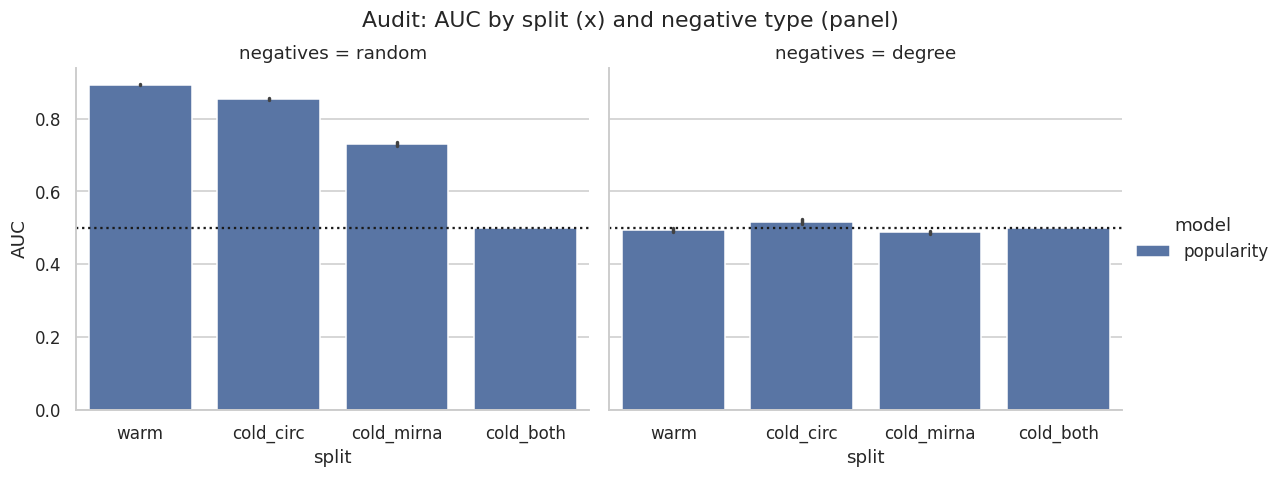

,warm+random (paper-style),cold_both+degree (hardest),drop
model,,,
popularity,0.893,0.5,0.393


In [12]:
order = ["popularity","seq_only","seq+degree"] if RUN_MODELS else ["popularity"]
g = sns.catplot(data=R, x="split", y="AUC", hue="model", hue_order=order, col="negatives", kind="bar", order=SPLITS, errorbar="sd", height=4.2, aspect=1.25)
for ax in g.axes.ravel(): ax.axhline(0.5, color="k", ls=":")
g.fig.suptitle("Audit: AUC by split (x) and negative type (panel)", y=1.03); plt.savefig(f"{PROC}/fig_audit_auc.png", bbox_inches="tight"); plt.show()

M = R.groupby(["model","split","negatives"]).AUC.mean().unstack(["negatives"])
drop = pd.DataFrame({"warm+random (paper-style)": M.xs("warm", level="split")["random"], "cold_both+degree (hardest)": M.xs("cold_both", level="split")["degree"]}); drop["drop"] = drop.iloc[:,0]-drop.iloc[:,1]
display(drop.round(3))

# Part E: HMA-GCA v2 (node-held-out validation, 4 variants, extra seeds)

Results are appended to `results_hmagca/results.csv` after every run, and finished runs are skipped if you re-run the cell, so an interrupted run can be resumed.

**Timing:** each run trains on ~33k pairs for up to 50 epochs. On a GPU expect roughly 1 minute per run, on CPU several minutes. The full grid is 4 splits × 5 folds × 3 variants × seeds = 60 runs per seed. Start with `FOLDS_TO_RUN = [0]` to check everything works.

In [13]:
RES_PATH = f"{RES}/results_v2.csv"
cols = ["model","split","fold","seed","negatives","AUC","AUPR","val_AUC","epochs","n_train_rows","n_val_rows"]
done = pd.read_csv(RES_PATH) if os.path.exists(RES_PATH) else pd.DataFrame(columns=cols)
done_keys = set(zip(done.model, done.split, done.fold, done.seed)); rows = done.to_dict("records")

def split_train_val(df, split, rng):
    """warm: random 10% of pairs. cold splits: hold out whole nodes so validation is cold like the test set."""
    if split == "warm":
        idx = rng.permutation(len(df)); nv = int(0.10 * len(df)); return df.iloc[idx[nv:]], df.iloc[idx[:nv]]
    fr = 0.15 if split == "cold_both" else 0.10
    cs, ms = np.unique(df.circ), np.unique(df.mi)
    vc = set(rng.choice(cs, max(1, int(fr * len(cs))), replace=False)) if split in ("cold_circ", "cold_both") else set()
    vm = set(rng.choice(ms, max(1, int(fr * len(ms))), replace=False)) if split in ("cold_mirna", "cold_both") else set()
    cv = df.circ.isin(vc).values; mv = df.mi.isin(vm).values
    if split == "cold_circ": isv, ist = cv, ~cv
    elif split == "cold_mirna": isv, ist = mv, ~mv
    else: isv, ist = cv & mv, ~cv & ~mv
    return df[ist], df[isv]

t_all = time.time(); stop = False; n_new = 0
for seeds, variants in PASSES:
    for seed in seeds:
        for fold in FOLDS_TO_RUN:
            for split in SPLIT_ORDER:
                todo = [v for v in variants if (f"HMA-GCA:{v}", split, fold, seed) not in done_keys]
                if not todo: continue
                if (time.time() - t_all) / 60 > TIME_BUDGET_MIN: stop = True; break
                d = S[(S.split == split) & (S.fold == fold)]; tr_all = d[d.part == "train"]
                tr, va = split_train_val(tr_all, split, np.random.default_rng(1000 * seed + fold))
                assert va.label.nunique() == 2 and len(va) > 50, f"validation set too small/one-class for {split} fold {fold}"
                tp = tr[tr.label == 1]; dc = np.bincount(tp.circ, minlength=nc).astype(float); dm = np.bincount(tp.mi, minlength=nm).astype(float)
                for variant in todo:
                    name = f"HMA-GCA:{variant}"; t0 = time.time(); c_in, m_in = build_inputs(dc, dm, variant)
                    model, vauc, ep = train_one(c_in, m_in, tr, va, seed)
                    for neg in ["random", "degree"]:
                        te = d[d.part == f"test_{neg}"]; s_ = predict(model, c_in, m_in, te)
                        rows.append(dict(model=name, split=split, fold=fold, seed=seed, negatives=neg, AUC=roc_auc_score(te.label, s_), AUPR=average_precision_score(te.label, s_),
                                         val_AUC=vauc, epochs=ep, n_train_rows=len(tr), n_val_rows=len(va)))
                    pd.DataFrame(rows).to_csv(RES_PATH, index=False); n_new += 1
                    print(f"seed {seed} | fold {fold} | {split:10s} | {name:28s} | val AUC {vauc:.3f} | epochs {ep:2d} | {time.time()-t0:3.0f}s | elapsed {(time.time()-t_all)/60:.1f} min")
            if stop: break
        if stop: break
    if stop: break
H = pd.DataFrame(rows)
print(("STOPPED by time budget" if stop else "ALL PLANNED RUNS FINISHED"), f"- {n_new} new runs this session, {len(H)//2} runs in {RES_PATH}")
if stop: print("Re-run this cell to resume where it stopped (it skips finished runs), or move on to Part F.")

seed 42 | fold 0 | cold_mirna | HMA-GCA:no_degree            | val AUC 0.874 | epochs 36 |  50s | elapsed 0.8 min
seed 42 | fold 0 | cold_mirna | HMA-GCA:full                 | val AUC 0.782 | epochs 18 |  39s | elapsed 1.5 min
seed 42 | fold 0 | cold_mirna | HMA-GCA:no_degree+no_manifold | val AUC 0.873 | epochs 40 |  24s | elapsed 1.9 min
seed 42 | fold 0 | cold_mirna | HMA-GCA:no_manifold          | val AUC 0.866 | epochs 28 |  17s | elapsed 2.2 min
seed 42 | fold 0 | cold_both  | HMA-GCA:no_degree            | val AUC 0.821 | epochs 44 |  16s | elapsed 2.4 min
seed 42 | fold 0 | cold_both  | HMA-GCA:full                 | val AUC 0.594 | epochs 20 |  35s | elapsed 3.0 min
seed 42 | fold 0 | cold_both  | HMA-GCA:no_degree+no_manifold | val AUC 0.834 | epochs 30 |  11s | elapsed 3.2 min
seed 42 | fold 0 | cold_both  | HMA-GCA:no_manifold          | val AUC 0.734 | epochs 50 |  18s | elapsed 3.5 min
seed 42 | fold 0 | cold_circ  | HMA-GCA:no_degree            | val AUC 0.951 | epochs 

# Part F: comparison, paired tests, seed spread

split                         cold_both        cold_circ        cold_mirna  \
negatives                        degree random    degree random     degree   
model                                                                        
HMA-GCA:full                      0.556  0.546     0.842  0.937      0.590   
HMA-GCA:no_degree                 0.680  0.809     0.857  0.961      0.689   
HMA-GCA:no_degree+no_manifold     0.671  0.795     0.859  0.960      0.699   
HMA-GCA:no_manifold               0.640  0.721     0.832  0.950      0.658   
popularity                        0.500  0.500     0.517  0.853      0.488   

split                                  warm         
negatives                     random degree random  
model                                               
HMA-GCA:full                   0.721  0.817  0.958  
HMA-GCA:no_degree              0.820  0.863  0.967  
HMA-GCA:no_degree+no_manifold  0.830  0.865  0.966  
HMA-GCA:no_manifold            0.804  0.817  0.965  
popularity                     0.730  0.494  0.893


=== no_degree  minus  full  (paired over folds and seeds; wins = how many pairs favour no_degree) ===


mean_diff    std  n_pairs  wins
split      negatives                                 
cold_both  degree         0.124  0.041       15    15
           random         0.262  0.048       15    15
cold_circ  degree         0.016  0.011       15    13
           random         0.023  0.005       15    15
cold_mirna degree         0.099  0.033       15    15
           random         0.099  0.035       15    15
warm       degree         0.046  0.011       15    15
           random         0.008  0.003       15    15


=== no_degree+no_manifold  minus  no_degree  (paired over folds and seeds; wins = how many pairs favour no_degree+no_manifold) ===


mean_diff    std  n_pairs  wins
split      negatives                                 
cold_both  degree        -0.005  0.039        5     3
           random        -0.011  0.012        5     1
cold_circ  degree         0.005  0.005        5     4
           random        -0.001  0.001        5     1
cold_mirna degree         0.014  0.061        5     4
           random         0.008  0.020        5     4
warm       degree         0.002  0.007        5     3
           random        -0.001  0.002        5     2


=== no_manifold  minus  full  (paired over folds and seeds; wins = how many pairs favour no_manifold) ===


mean_diff    std  n_pairs  wins
split      negatives                                 
cold_both  degree         0.071  0.070        5     4
           random         0.167  0.055        5     5
cold_circ  degree        -0.015  0.015        5     1
           random         0.012  0.002        5     5
cold_mirna degree         0.083  0.019        5     5
           random         0.081  0.027        5     5
warm       degree         0.002  0.003        5     3
           random         0.007  0.002        5     5


=== seed-to-seed spread: mean AUC per seed ===


seed                                       42     43     44
model             split      negatives                     
HMA-GCA:full      cold_both  degree     0.569  0.547  0.554
                             random     0.554  0.543  0.543
                  cold_circ  degree     0.847  0.836  0.842
                             random     0.938  0.937  0.937
                  cold_mirna degree     0.575  0.590  0.605
                             random     0.723  0.723  0.718
                  warm       degree     0.815  0.820  0.815
                             random     0.958  0.959  0.958
HMA-GCA:no_degree cold_both  degree     0.675  0.679  0.686
                             random     0.806  0.808  0.811
                  cold_circ  degree     0.855  0.857  0.859
                             random     0.961  0.961  0.961
                  cold_mirna degree     0.685  0.699  0.682
                             random     0.822  0.824  0.814
                  warm       degree     0.863  0.860  0.866
                             random     0.967  0.966  0.967

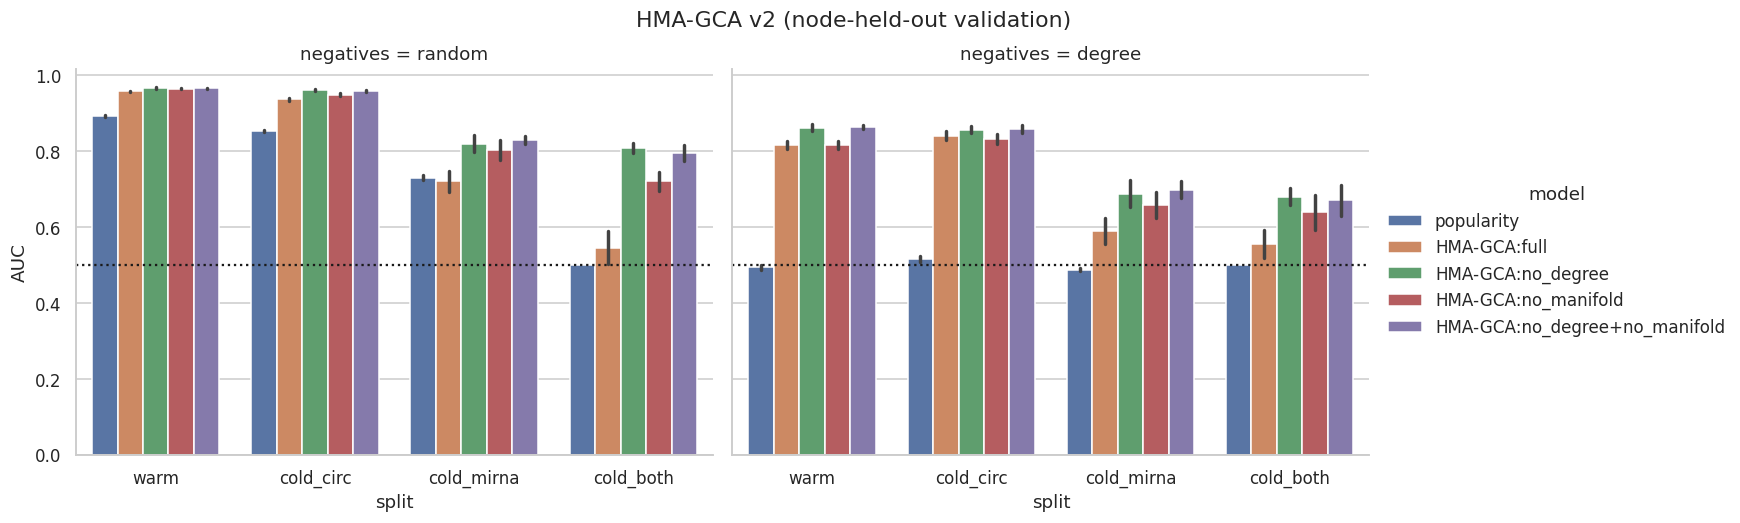


validation AUC vs test AUC (random negatives), mean:


val_AUC    AUC
model                         split                     
HMA-GCA:full                  cold_both     0.564  0.546
                              cold_circ     0.938  0.937
                              cold_mirna    0.724  0.721
                              warm          0.960  0.958
HMA-GCA:no_degree             cold_both     0.815  0.809
                              cold_circ     0.961  0.961
                              cold_mirna    0.844  0.820
                              warm          0.968  0.967
HMA-GCA:no_degree+no_manifold cold_both     0.800  0.795
                              cold_circ     0.960  0.960
                              cold_mirna    0.854  0.830
                              warm          0.967  0.966
HMA-GCA:no_manifold           cold_both     0.735  0.721
                              cold_circ     0.951  0.950
                              cold_mirna    0.836  0.804
                              warm          0.966  0.965

In [14]:
H = pd.read_csv(RES_PATH)
pop = pd.read_csv(f"{PROC}/audit_results_per_fold.csv"); pop = pop[pop.model == "popularity"].assign(seed=42)
A_ = pd.concat([pop[["model","split","fold","seed","negatives","AUC"]], H[["model","split","fold","seed","negatives","AUC"]]], ignore_index=True)
summ = A_.groupby(["model","split","negatives"]).AUC.agg(["mean","std","count"]).round(3); summ.to_csv(f"{RES}/comparison_summary_v2.csv")
display(A_.groupby(["model","split","negatives"]).AUC.mean().unstack(["split","negatives"]).round(3))

def paired(a, b):
    X = H.pivot_table(index=["split","negatives","seed","fold"], columns="model", values="AUC")
    if f"HMA-GCA:{a}" not in X or f"HMA-GCA:{b}" not in X: return None
    dd = (X[f"HMA-GCA:{a}"] - X[f"HMA-GCA:{b}"]).dropna().groupby(["split","negatives"]).agg(["mean","std","count",lambda x: int((x > 0).sum())])
    dd.columns = ["mean_diff","std","n_pairs","wins"]; return dd.round(3)
for a, b in [("no_degree","full"), ("no_degree+no_manifold","no_degree"), ("no_manifold","full")]:
    r_ = paired(a, b)
    if r_ is not None: print(f"\n=== {a}  minus  {b}  (paired over folds and seeds; wins = how many pairs favour {a}) ==="); display(r_)

print("\n=== seed-to-seed spread: mean AUC per seed ===")
sp = H[H.model.isin(["HMA-GCA:full","HMA-GCA:no_degree"])].groupby(["model","split","negatives","seed"]).AUC.mean().unstack("seed").round(3); display(sp)

order = ["popularity"] + [f"HMA-GCA:{v}" for v in ["full","no_degree","no_manifold","no_degree+no_manifold"]]
g = sns.catplot(data=A_, x="split", y="AUC", hue="model", hue_order=[o for o in order if o in A_.model.unique()], col="negatives", kind="bar", order=[s for s in ["warm","cold_circ","cold_mirna","cold_both"] if s in A_.split.unique()], errorbar="sd", height=4.6, aspect=1.4)
for ax in g.axes.ravel(): ax.axhline(0.5, color="k", ls=":")
g.fig.suptitle("HMA-GCA v2 (node-held-out validation)", y=1.03); plt.savefig(f"{RES}/fig_hmagca_v2.png", bbox_inches="tight"); plt.show()
print("\nvalidation AUC vs test AUC (random negatives), mean:"); display(H[H.negatives == "random"].groupby(["model","split"])[["val_AUC","AUC"]].mean().round(3))

### How to read the results
- **`val_AUC` close to `AUC` on cold splits** means the new validation is honest (in v1 it was 0.97 vs 0.54).
- **`no_degree` vs `full`** (paired table): confirms or refutes the finding that the degree feature breaks cold-start.
- **`no_degree+no_manifold` vs `no_degree`**: the clean test of the paper's PCA+UMAP idea. A difference near 0 means the manifold step does nothing.
- **Seed spread table**: if the gaps above are larger than the spread across seeds 42/43/44, they are real.

In [15]:
import shutil
shutil.make_archive(f"{BASE}/results_hmagca_v2", "zip", RES)
print("Saved:", f"{BASE}/results_hmagca_v2.zip", "-> download it from the Output tab")

Saved: /kaggle/working/results_hmagca_v2.zip -> download it from the Output tab
